# 📚 03 - Using Help and Documentation

One of the most important skills in programming is knowing **how to get help**. Nobody memorizes every function. Good programmers know how to **investigate** unfamiliar code quickly. Jupyter/IPython have built-in tools for exactly that.

## ✅ Learning Goals
- Use `?`, `??`, and `help()` to read documentation and source code
- Use tab completion, hover, and `dir()` to discover names and methods
- Check an object's type and structure before looking anything up
- Read a function signature, including default values and the `/` and `*` markers
- Read an error message from the bottom up, and recognize the common error types
- Find, search, and trust the right **official** documentation
- Follow a step-by-step help workflow for unfamiliar code

> **The core habit:** use Jupyter's built-in tools to ask small questions quickly, then use the official documentation to understand the full answer.

## Setup
This notebook pokes at a few libraries you haven't studied yet, NumPy, Matplotlib, and Pandas. That's on purpose: these tools are **how** you explore a library you don't know. Following the habit from notebook 02, all the imports go in the first cell.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 1. Using `?` for Quick Help

Put a question mark **after** a name to see its documentation: the **signature** (what arguments it takes), a description, its parameters, and what it returns.

Use `?` when your question is: *"What does this do, and what arguments does it accept?"*

⚠️ The `?` must be the **last thing on the line**. `len?  # help for len` is a `SyntaxError`, so put comments on their own line.

In [2]:
# Show help for the built-in len() function
len?

Signature: len(obj, /)
Docstring: Return the number of items in a container.
Type:      builtin_function_or_method

In [3]:
# Show help for print()
print?

Signature: print(*args, sep=' ', end='\n', file=None, flush=False)
Docstring:
Prints the values to a stream, or to sys.stdout by default.

sep
  string inserted between values, default a space.
end
  string appended after the last value, default a newline.
file
  a file-like object (stream); defaults to the current sys.stdout.
flush
  whether to forcibly flush the stream.
Type:      builtin_function_or_method

In [4]:
# Works on library functions too
np.arange?

Signature:
np.arange(
    start_or_stop,
    /,
    stop=None,
    step=1,
    *,
    dtype=None,
    device=None,
    like=None,
)
Docstring:
arange([start,] stop[, step,], dtype=None, *, device=None, like=None)

Return evenly spaced values within a given interval.

``arange`` can be called with a varying number of positional arguments:

* ``arange(stop)``: Values are generated within the half-open interval
  ``[0, stop)`` (in other words, the interval including `start` but
  excluding `stop`).
* ``arange(start, stop)``: Values are generated within the half-open
  interval ``[start, stop)``.
* ``arange(start, stop, step)`` Values are generated within the half-open
  interval ``[start, stop)``, with spacing between values given by
  ``step``.

For integer arguments the function is roughly equivalent to the Python
built-in :py:class:`range`, but returns an ndarray rather than a ``range``
instance.

When using a non-integer step, such as 0.1, it is often better to use
`numpy.linspace`.



### Searching with Wildcards
Don't know the exact name? Put `*` around part of it, and `?` lists every match:

In [5]:
np.*mean*?

np.mean
np.nanmean

✅ **Your Turn**:
1. Use `?` to check the documentation for `range` and `dict`.
2. Use `?` on `np.arange`. Which of its arguments are required, and which are optional?
3. Use a wildcard search to find every NumPy name containing `sort`.

In [6]:
# Your turn here
range?


Init signature: range(self, /, *args, **kwargs)
Docstring:     
range(stop) -> range object
range(start, stop[, step]) -> range object

Return an object that produces a sequence of integers from start (inclusive)
to stop (exclusive) by step.  range(i, j) produces i, i+1, i+2, ..., j-1.
start defaults to 0, and stop is omitted!  range(4) produces 0, 1, 2, 3.
These are exactly the valid indices for a list of 4 elements.
When step is given, it specifies the increment (or decrement).
Type:           type
Subclasses:     

In [7]:
dict?

Init signature: dict(self, /, *args, **kwargs)
Docstring:     
dict() -> new empty dictionary
dict(mapping) -> new dictionary initialized from a mapping object's
    (key, value) pairs
dict(iterable) -> new dictionary initialized as if via:
    d = {}
    for k, v in iterable:
        d[k] = v
dict(**kwargs) -> new dictionary initialized with the name=value pairs
    in the keyword argument list.  For example:  dict(one=1, two=2)
Type:           type
Subclasses:     OrderedDict, defaultdict, Counter, EnumDict, Bunch, _Quoter, ObjectDict, ConvertingDict, Config, _DefaultOptionDict, ...

In [8]:
np.arange?
# Required arguments: stop
# Optional arguments: start, step, dtype, device, like

Signature:
np.arange(
    start_or_stop,
    /,
    stop=None,
    step=1,
    *,
    dtype=None,
    device=None,
    like=None,
)
Docstring:
arange([start,] stop[, step,], dtype=None, *, device=None, like=None)

Return evenly spaced values within a given interval.

``arange`` can be called with a varying number of positional arguments:

* ``arange(stop)``: Values are generated within the half-open interval
  ``[0, stop)`` (in other words, the interval including `start` but
  excluding `stop`).
* ``arange(start, stop)``: Values are generated within the half-open
  interval ``[start, stop)``.
* ``arange(start, stop, step)`` Values are generated within the half-open
  interval ``[start, stop)``, with spacing between values given by
  ``step``.

For integer arguments the function is roughly equivalent to the Python
built-in :py:class:`range`, but returns an ndarray rather than a ``range``
instance.

When using a non-integer step, such as 0.1, it is often better to use
`numpy.linspace`.



In [9]:
np.*sort*?

np.argsort
np.lexsort
np.searchsorted
np.sort
np.sort_complex

## 2. Using `??` for Source Code (if available)
`??` tries to show you the actual **source code**, not just the docstring. Use it when your question is: *"How does this work inside?"*

It won't work for everything. Many built-ins and much of NumPy are implemented in C (compiled code), not Python, so there's no Python source to show. You'll just get the docstring again.

In [10]:
# Try to view source code for sum(), a built-in written in C
sum??

Signature: sum(iterable, /, start=0)
Docstring:
Return the sum of a 'start' value (default: 0) plus an iterable of numbers

When the iterable is empty, return the start value.
This function is intended specifically for use with numeric values and
may reject non-numeric types.
Type:      builtin_function_or_method

Functions **you** write are always plain Python, so `??` shows their source:

In [11]:
def calculate_tax(price, rate=0.08):
    """Return the sales tax on a price."""
    return price * rate

calculate_tax??

Signature: calculate_tax(price, rate=0.08)
Source:   
def calculate_tax(price, rate=0.08):
    """Return the sales tax on a price."""
    return price * rate
File:      ~\appdata\local\temp\ipykernel_16688\3421356081.py
Type:      function

💡 Notice that the text in triple quotes, the **docstring**, is what `?` displays. Write one for your own functions, and `?` will work on them too.

💡 **In VS Code**, right-click a name and choose **Go to Definition** (or press `F12`) to jump to its source code. This works for many library functions too.

✅ **Your Turn**:
1. Use `??` on `pd.read_csv` and see whether you get more detail than `?` gave you.
2. Write a small function of your own, with a docstring, and try both `?` and `??` on it.

In [12]:
# Your turn here
# 1.
pd.read_csv??

def difference(a, b):
    """Return the difference between two numbers."""
    return a - b


Signature:
pd.read_csv(
    filepath_or_buffer: 'FilePath | ReadCsvBuffer[bytes] | ReadCsvBuffer[str]',
    *,
    sep: 'str | None | lib.NoDefault' = <no_default>,
    delimiter: 'str | None | lib.NoDefault' = None,
    header: "int | Sequence[int] | None | Literal['infer']" = 'infer',
    names: 'Sequence[Hashable] | None | lib.NoDefault' = <no_default>,
    index_col: 'IndexLabel | Literal[False] | None' = None,
    usecols: 'UsecolsArgType' = None,
    dtype: 'DtypeArg | None' = None,
    engine: 'CSVEngine | None' = None,
    converters: 'Mapping[HashableT, Callable] | None' = None,
    true_values: 'list | None' = None,
    false_values: 'list | None' = None,
    skipinitialspace: 'bool' = False,
    skiprows: 'list[int] | int | Callable[[Hashable], bool] | None' = None,
    skipfooter: 'int' = 0,
    nrows: 'int | None' = None,
    na_values: 'Hashable | Iterable[Hashable] | Mapping[Hashable, Iterable[Hashable]] | None' = None,
    keep_default_na: 'bool' = True,
    na_filter: 

In [13]:
difference?

Signature: difference(a, b)
Docstring: Return the difference between two numbers.
File:      ~\appdata\local\temp\ipykernel_16688\3808106528.py
Type:      function

In [14]:
difference??

Signature: difference(a, b)
Source:   
def difference(a, b):
    """Return the difference between two numbers."""
    return a - b
File:      ~\appdata\local\temp\ipykernel_16688\3808106528.py
Type:      function

## 3. The `help()` Function
`help()` is the plain built-in Python equivalent of `?` — it works the same way outside of Jupyter too, e.g. in a plain `.py` script run from the terminal.

In [15]:
help(len)

Help on built-in function len in module builtins:

len(obj, /)
    Return the number of items in a container.



In [16]:
import math
help(math.sqrt)

Help on built-in function sqrt in module math:

sqrt(x, /)
    Return the square root of x.



✅ **Your Turn**:
1. Use `help()` to explore `list.append` or `str.upper`.
2. Use `help(dict.get)` to learn what `.get()` does. Then create a dictionary and use `.get()` to look up a key that **doesn't** exist, without getting an error.

In [17]:
# Your turn here
help(list.append)

Help on method_descriptor:

append(self, object, /) unbound builtins.list method
    Append object to the end of the list.



In [18]:
help(dict.get)

Help on method_descriptor:

get(self, key, default=None, /) unbound builtins.dict method
    Return the value for key if key is in the dictionary, else default.



In [19]:
# create a simple dictionary
simple_ID = {'name': 'Charles', 'age': 31, 'city': 'Tampa'}

simple_ID.get('birthday')

## 4. Tab Completion

Type the start of a name, or an object followed by a dot, and press `Tab` to see what's available:

```python
np.ar<TAB>        # arange, arccos, arcsin, array, ...
mylist = []
mylist.<TAB>      # append, clear, copy, count, ...
```

Tab completion helps you discover functions, avoid typos, and check spelling and capitalization.

### In VS Code
VS Code's **IntelliSense** goes further than classic Jupyter:
- Suggestions pop up **automatically** as you type. If they don't, press `Ctrl` + `Space`, and press `Tab` or `Enter` to accept one.
- **Hover** over any function name to see its documentation in a tooltip.
- Type a function name and `(`, and VS Code shows the **parameter hints**, with the argument you're currently typing in bold.

⚠️ Completion only knows about variables that **exist in the kernel**. Run the cell that creates `mylist` first, then use completion on `mylist.` in a later cell.

✅ **Your Turn**:
1. Create a dictionary, run the cell, and use tab completion to explore its methods.
2. Run `names = ['Ada', 'Grace', 'Katherine']`, then type `names.` and use completion to find the method that adds an item to the list.

In [20]:
# Your turn here
student = {'name': 'Eli', 'age': 21, 'major': 'Computer Science'}
# Methods include .get(), .keys(), .values(), etc...

names = ['Ada', 'Grace,', 'Katherine']
names.append('Zeke')

## 5. Listing Everything with `dir()`
`dir(obj)` lists **every** name an object has. It's noisier than tab completion, but it returns a real Python list that you can filter:

In [21]:
scores = [82, 91, 76]
print(dir(scores))

['__add__', '__class__', '__class_getitem__', '__contains__', '__delattr__', '__delitem__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__iadd__', '__imul__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__mul__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__reversed__', '__rmul__', '__setattr__', '__setitem__', '__sizeof__', '__str__', '__subclasshook__', 'append', 'clear', 'copy', 'count', 'extend', 'index', 'insert', 'pop', 'remove', 'reverse', 'sort']


The names wrapped in double underscores (`__len__`, `__init__`, ...) are Python's internal machinery. You don't need them yet. Filter them out to see the methods meant for you:

In [22]:
[name for name in dir(scores) if not name.startswith('_')]

['append',
 'clear',
 'copy',
 'count',
 'extend',
 'index',
 'insert',
 'pop',
 'remove',
 'reverse',
 'sort']

In [23]:
# Or search a whole library for a keyword
[name for name in dir(np) if 'mean' in name]

['mean', 'nanmean']

✅ **Your Turn**: Use `dir()` on a string (like `'hello'`) and filter out the underscore names. Find the method that changes text to UPPERCASE, and one other method you've never used. Try both.

In [24]:
# Your turn here
[name for name in dir('hello') if not name.startswith('_')]

['capitalize',
 'casefold',
 'center',
 'count',
 'encode',
 'endswith',
 'expandtabs',
 'find',
 'format',
 'format_map',
 'index',
 'isalnum',
 'isalpha',
 'isascii',
 'isdecimal',
 'isdigit',
 'isidentifier',
 'islower',
 'isnumeric',
 'isprintable',
 'isspace',
 'istitle',
 'isupper',
 'join',
 'ljust',
 'lower',
 'lstrip',
 'maketrans',
 'partition',
 'removeprefix',
 'removesuffix',
 'replace',
 'rfind',
 'rindex',
 'rjust',
 'rpartition',
 'rsplit',
 'rstrip',
 'split',
 'splitlines',
 'startswith',
 'strip',
 'swapcase',
 'title',
 'translate',
 'upper',
 'zfill']

## 6. Check the Type and Structure First
Before you look anything up, find out **what kind of object** you have. The right documentation depends on it. A list, a NumPy array, and a DataFrame all have different methods.

In [25]:
print(type([1, 2, 3]))
print(type(np.array([1, 2, 3])))
print(type(pd.DataFrame({'a': [1, 2]})))
print(type(plt))

<class 'list'>
<class 'numpy.ndarray'>
<class 'pandas.DataFrame'>
<class 'module'>


Arrays and DataFrames also tell you their **shape** (rows, columns) and the type of data they hold:

In [26]:
data = np.array([[1, 2, 3], [4, 5, 6]])

print('shape:', data.shape)   # 2 rows, 3 columns
print('dtype:', data.dtype)   # type of each element
print('ndim: ', data.ndim)    # number of dimensions

shape: (2, 3)
dtype: int64
ndim:  2


💡 **A quick debugging pattern.** When something behaves strangely, check `type(x)` first, then `len(x)` or `x.shape`, then look at a small piece with `x[:5]`. This often reveals the real problem, such as a string where you expected a number, or a list where you expected an array.

## 7. Reading Function Signatures
The **signature** at the top of `?` output tells you exactly what a function accepts. Here's `np.linspace`:

```text
linspace(start, stop, num=50, endpoint=True, ...)
```
- `start` and `stop` have no `=`, so they're **required**.
- `num=50` is **optional**, and it defaults to 50 if you leave it out.
- `endpoint=True` is optional, and defaults to `True`.

In [27]:
print(np.linspace(0, 10, num=5))
print(np.linspace(start=0, stop=10, num=5))   # same thing, more readable

[ 0.   2.5  5.   7.5 10. ]
[ 0.   2.5  5.   7.5 10. ]


### The `/` and `*` Markers
Some signatures contain a bare `/` or `*`. Run the cell below and look at the signature:

In [28]:
sorted?

Signature: sorted(iterable, /, *, key=None, reverse=False)
Docstring:
Return a new list containing all items from the iterable in ascending order.

A custom key function can be supplied to customize the sort order, and the
reverse flag can be set to request the result in descending order.
Type:      builtin_function_or_method

```text
sorted(iterable, /, *, key=None, reverse=False)
```
- Arguments **before `/`** must be passed by **position**: `sorted(my_list)`, not `sorted(iterable=my_list)`.
- Arguments **after `*`** must be passed by **name**: `sorted(my_list, reverse=True)`, not `sorted(my_list, None, True)`.

You'll also see `*args` (any number of extra positional arguments) and `**kwargs` (any number of extra named arguments). Those were covered in Module 04.

## 8. Reading Error Messages
An error message (a **traceback**) can look scary, but there's a trick: **read the last line first**. It names the error type and says what went wrong. The lines above it show *where* it happened.

The cell below fails **on purpose**:

In [29]:
numbers = [1, 2, 3]
# numbers.mean()

`AttributeError: 'list' object has no attribute 'mean'` means that a Python **list** doesn't have a `.mean()` method. (A NumPy array does.) Two fixes:

In [30]:
print(np.mean(numbers))          # use a function that accepts a list
print(np.array(numbers).mean())  # or convert to an array, which has .mean()

2.0
2.0


🔁 **Before you Restart & Run All:** Run All stops at the first error, so this deliberate error would keep every cell after it from running (see notebook 02). Once you've read the error, comment out the `numbers.mean()` line in the cell above (`Ctrl+/`, or `Cmd+/` on Mac). Do the same with any error you create on purpose in the Your Turn below.

### Common Error Types

| Error | Usually means... |
|---|---|
| `NameError` | A name isn't defined: a typo, or a cell you haven't run (see notebook 02) |
| `TypeError` | Wrong type for the operation, like `'5' + 5`, or the wrong number of arguments |
| `AttributeError` | That type of object doesn't have that method or attribute |
| `ValueError` | Right type, bad value, like `int('hello')` |
| `KeyError` | That key isn't in the dictionary (or column in the DataFrame) |
| `IndexError` | The position is past the end of the list |
| `ModuleNotFoundError` | The package isn't installed in this environment. Use `%pip install` (notebook 01) |
| `FileNotFoundError` | Wrong path or working directory |
| `SyntaxError` | Python can't even read the code: a missing `:`, `)`, or quote |

**Debugging questions to ask:**
1. What **type** is this object?
2. Is the name **spelled** correctly (including capitals)?
3. Does this method **belong** to this type of object?
4. What **arguments** does the function expect? (Check with `?`.)
5. Which **line number** and which **name** does the error point to?

✅ **Your Turn**: Run the code below. Read the error from the bottom up, and explain it in a comment. Then fix it so that `5` gets added to a **list** along with `12`.
```python
number = 12
number.append(5)
```

In [31]:
# Your turn here
# number = 12
# number.append(5) - This raises an AttirbuteError because integer objects do not have an append method.
numbers = [12]
numbers.append(5)


## 9. External Documentation

For the full story (every parameter, version-specific behavior, complete examples), go to the **official** documentation, maintained by the project itself:

| Tool | Official docs |
|---|---|
| Python | [docs.python.org/3](https://docs.python.org/3/) |
| Jupyter | [docs.jupyter.org](https://docs.jupyter.org/) |
| NumPy | [numpy.org/doc](https://numpy.org/doc/) |
| Matplotlib | [matplotlib.org/stable](https://matplotlib.org/stable/) |
| Pandas | [pandas.pydata.org/docs](https://pandas.pydata.org/docs/) |

Library docs usually have two main parts:
- **User Guide / Tutorials** explain concepts and workflows. Read these to **learn** a topic.
- **API Reference** lists every function, its parameters, and its return values. Use this to **look things up**.

Matplotlib also has a **Gallery** of complete example charts with their code. Find one close to what you want and adapt the smallest example.

### Match the Docs to Your Version
Libraries change between versions, and the docs have a version switcher. Check which versions you have:

In [32]:
print('NumPy:     ', np.__version__)
print('Pandas:    ', pd.__version__)
import matplotlib
print('Matplotlib:', matplotlib.__version__)

NumPy:      2.5.3
Pandas:     3.0.6
Matplotlib: 3.11.1


### Searching Effectively
Include the **library**, the **function**, and the **task**:
- ❌ `why does python hate me`
- ✅ `numpy mean ignore nan`
- ✅ `matplotlib scatter plot change marker size`
- ✅ `pandas read_csv site:pandas.pydata.org` (`site:` limits the search to the official docs)
- ✅ For an error, paste the **exact last line** in quotes: `"TypeError: can only concatenate str (not \"int\") to str"`

Tutorials, videos, Q&A sites, and AI assistants are great for **explanations**. Follow your course's policy on AI tools, and give them your exact code and error. But **verify** the important details against the official docs, because they can be outdated or confidently wrong.

✅ **Your Turn**: Look up the official Matplotlib documentation for `plt.bar`. In the cell below, write the **smallest** bar chart that works, using the docs' required arguments only. Then add a title and axis labels, one at a time, re-running after each change so you can see what each one does.

Text(0, 0.5, 'Value')

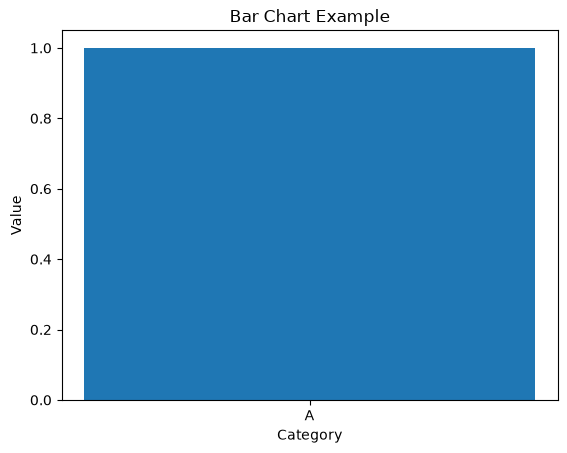

In [33]:
#Matplotlib documentation for plt.bar
plt.bar(['A'], [1])
plt.title('Bar Chart Example')
plt.xlabel('Category')
plt.ylabel('Value')

## 10. Help for Magic Commands
The `?` trick works on magic commands too (see notebook 01). `%lsmagic` lists every magic, and `%magic` prints a long guide to all of them.

In [34]:
%timeit?

Docstring:
Time execution of a Python statement or expression

**Usage, in line mode**::

  %timeit [-n<N> -r<R> [-t|-c] -q -p<P> [-o|-v <V>]] statement

**or in cell mode**::

  %%timeit [-n<N> -r<R> [-t|-c] -q -p<P> [-o|-v <V>]] setup_code
  code
  code...

Time execution of a Python statement or expression using the timeit
module.  This function can be used both as a line and cell magic:

- In line mode you can time a single-line statement (though multiple
  ones can be chained with using semicolons).

- In cell mode, the statement in the first line is used as setup code
  (executed but not timed) and the body of the cell is timed.  The cell
  body has access to any variables created in the setup code.

Options:

-n<N>
  Execute the given statement N times in a loop. If N is not
  provided, N is determined so as to get sufficient accuracy.

-r<R>
  Number of repeats R, each consisting of N loops, and take the
  average result.
  Default: 7

-t
  Use ``time.time`` to measure the time

✅ **Your Turn**: Run `%lsmagic`, pick one magic you haven't used yet, and read its help with `?`. Describe in a comment what it does.

In [35]:
# Your turn here
%lsmagic
%colors?
 #Switches the color scheme of the IPython shell

Docstring:
Switch color scheme/theme globally for IPython

Examples
--------
To get a plain black and white terminal::

  %colors nocolor
File:      ~\projects\3603-data-science-coker\.venv\lib\site-packages\ipython\core\magics\basic.py

## 11. A Practical Help Workflow
When you run into unfamiliar code, work through these steps in order. Most questions get answered by step 3 or 4:
1. **Identify the type** of the object: `type(x)`.
2. **Discover names** with `Tab`, `dir()`, or a wildcard `?` search.
3. **Read quick docs** with `?`, or hover in VS Code.
4. **Try a tiny example** in a new cell.
5. **Read the source** with `??` if you need to know how it works inside.
6. **Read the official docs** for the full details.
7. **Search the exact error message** if the example fails.

**Example:** *How do I find the median of an array?*

In [36]:
data = np.array([3, 5, 8, 10])

# Steps 2–3: search for a name, then read its docs
np.*median*?

np.median
np.nanmedian

In [37]:
# Step 4: try a tiny example
np.median(data)

np.float64(6.5)

✅ **Your Turn**: Use the workflow to find out how to generate **ten random integers from 1 through 6** (like dice rolls) with `np.random.randint`. Read the docs carefully: is the upper limit **included** or **excluded**? Check your answer by generating 1,000 rolls and printing the smallest and largest values you get.

In [38]:
# Your turn here
# Step 1
type(np.random.randint)

# Step 2-3
np.random.*randint*?

# Step 4
np.random.randint(1, 7, size=10)


array([6, 1, 3, 5, 1, 6, 4, 6, 6, 2], dtype=int32)

np.random.randint

In [39]:
#Step 6 - upper limit is excluded
rolls = np.random.randint(1, 7, size=1000)

print(rolls.min(), rolls.max())

1 6


---
### Summary

| Tool | Answers the question... | Works outside Jupyter? |
|---|---|---|
| `x?` | What does this do, and what arguments does it take? | No |
| `x??` | How is it written inside (if the source is in Python)? | No |
| `help(x)` | Same as `?`, printed as output | ✅ Yes |
| `Tab` / hover | What names and methods are available? What do they do? | Editor feature |
| `dir(x)` | List **every** name, as a list I can filter | ✅ Yes |
| `type(x)` | What kind of object is this? | ✅ Yes |
| Official docs | Everything: full parameters, examples, versions | — |

- Read signatures: no `=` means required, `name=value` shows the default, `/` means positional only, `*` means named only.
- Read errors **from the bottom up**: the last line has the error type and the reason.
- Search with the library + function + task, and verify what you find against the official docs for **your** version.

## 🏋️ Practice

### Practice 1 — Read Before You Ask (easy)
Before looking anything up online, use `?` to answer: does `str.split()` split on *every* whitespace character by default, or just spaces? Write your answer as a comment.

In [40]:
str.split?

# Your answer as a comment here
#Yes, str.split() will split on every whitespace character by default


Signature: str.split(self, /, sep=None, maxsplit=-1)
Docstring:
Return a list of the substrings in the string, using sep as the separator string.

  sep
    The separator used to split the string.

    When set to None (the default value), will split on any
    whitespace character (including \n \r \t \f and spaces) and
    will discard empty strings from the result.
  maxsplit
    Maximum number of splits.
    -1 (the default value) means no limit.

Splitting starts at the front of the string and works to the end.

Note, str.split() is mainly useful for data that has been
intentionally delimited.  With natural text that includes
punctuation, consider using the regular expression module.
Type:      method_descriptor

### Practice 2 — Compare Two Functions (medium)
Use `help()` on both `sorted()` and `list.sort()`. Write a one-line comment explaining the key difference between them (hint: what each one returns).

In [41]:
# Your comparison here
help(sorted)
help(list.sort)

# help(sorted) returns a new list contains the sorted items, while list.sort() sorts the list and returns None.


Help on built-in function sorted in module builtins:

sorted(iterable, /, *, key=None, reverse=False)
    Return a new list containing all items from the iterable in ascending order.

    A custom key function can be supplied to customize the sort order, and the
    reverse flag can be set to request the result in descending order.

Help on method_descriptor:

sort(self, /, *, key=None, reverse=False) unbound builtins.list method
    Sort the list in ascending order and return None.

    The sort is in-place (i.e. the list itself is modified) and stable
    (i.e. the order of two equal elements is maintained).

    If a key function is given, apply it once to each list item and sort
    them, ascending or descending, according to their function values.

    The reverse flag can be set to sort in descending order.



### Practice 3 — Find It Yourself (harder)
Without searching online, use `?`, tab completion, and `dir()` on a string to find a string method you haven't used yet in this course. Try it out and explain what it does in a comment.

In [42]:
# Your discovery here
string = "Hello!"
string.casefold() # string.casefold() returns a case-insensitive version of the string for comparison purposes

'hello!'

### Practice 4 — Pick the Right Tool (medium)
In the Markdown cell below, describe in your own words when you would use each of these: `?`, `??`, `help()`, `Tab`, and `dir()`. For each one, give a situation where it's the **best** choice.

*Your answers here.*

'?' - Used for quick help with finding out what a method does and what it's arguments are
- When '?' is the **best** choice: You need a quick reminder for how a method works

'??' - Used for full source code if you need to know the inner workings of a method
- When '??' is the **best** choice: Determing whether a function is built from python or C

'help()' - Used as an alternative for '?' or '??"
- When 'help()' is the **best** choice: You are outside of a jupyter notebook

'Tab' - Used for discovering available methods for an object
- When 'Tab' is the **best** choice: You don't remember the name of a method

'dir()' - Used for listing every name an object has
- When 'dir()' is the **best** choice: You want to see a complete list of attributes for something


## 🔥 Challenge (Optional) — Explore a Library You've Never Used
Using **only** the built-in tools from this notebook (`?`, `??`, `help()`, `Tab`, `dir()`, wildcard search, and no web searching), explore Python's `datetime` and `statistics` modules:
1. `import datetime` and find out how to get **today's date**. Then find how to get the **day of the week** from it. (Is Monday 0 or 1? The docs will tell you.)
2. `import statistics` and find a function that returns the **most common** value in a list. Test it on `[3, 1, 3, 2, 3, 1]`.
3. Find a `statistics` function you didn't know existed, read its docs, and demonstrate it.

In comments, record **which tool** answered each question.

In [43]:
# Your exploration here
